# 07 · Phân tích lỗi

Chọn tổ hợp và đọc ma trận từ kết quả test đã lưu. Hàng là nhãn thật, cột là dự đoán.

Notebook chạy độc lập từ thư mục gốc hoặc `notebooks/`; cài `requirements-demo.txt` trước.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'student_success').exists(): ROOT = ROOT.parent
assert (ROOT/'student_success').exists(), 'Chạy từ thư mục dự án hoặc notebooks/'
sys.path.insert(0, str(ROOT))
from student_success.data import CATEGORICAL, NUMERIC, LABELS, SEED, split
DATA = ROOT/'data/raw/data.csv'
assert DATA.exists(), 'Chạy python scripts/download_data.py'
df = pd.read_csv(DATA, sep=';'); df.columns = df.columns.str.strip()
train_idx, test_idx = split(df)
train = df.loc[train_idx]
R = ROOT/'data/experiment'


,Dropout,Enrolled,Graduate
actual,,,
Dropout,138,29,117
Enrolled,56,24,79
Graduate,91,46,305


,actual,predicted,Số mẫu
0,Dropout,Enrolled,29
1,Dropout,Graduate,117
2,Enrolled,Dropout,56
3,Enrolled,Graduate,79
4,Graduate,Dropout,91
5,Graduate,Enrolled,46


,row_index,actual,predicted
2,510,Enrolled,Graduate
5,1787,Graduate,Dropout
8,1852,Graduate,Enrolled
9,1191,Graduate,Enrolled
13,3439,Dropout,Graduate
14,3158,Enrolled,Dropout
15,3394,Enrolled,Graduate
17,1717,Enrolled,Graduate
18,723,Dropout,Graduate
19,482,Dropout,Graduate


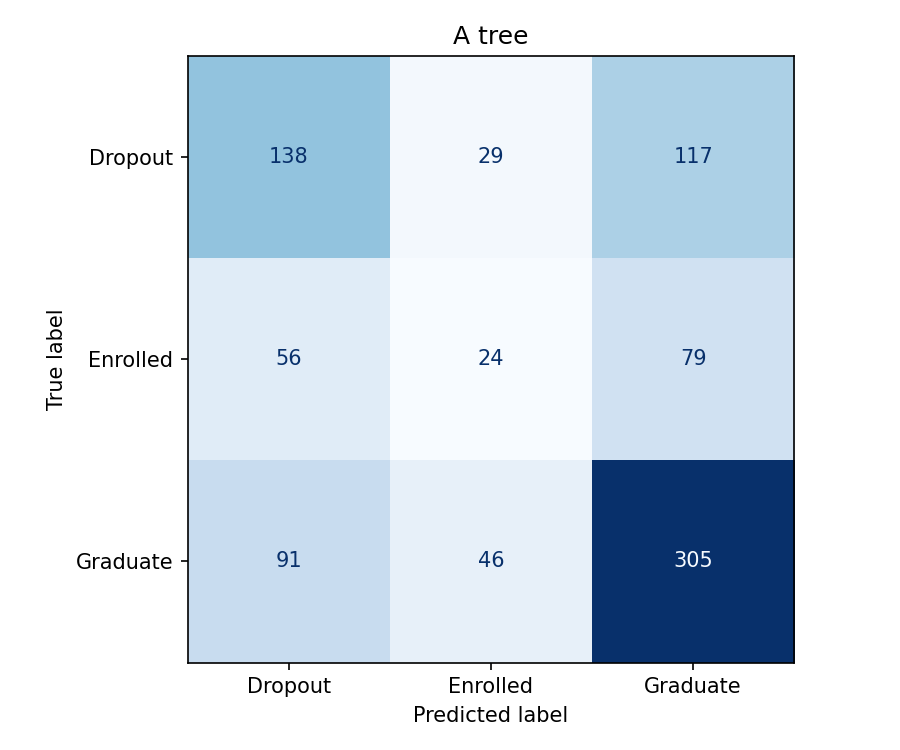

In [2]:
model='A_tree' # Đổi thành A_knn, B_knn hoặc B_tree
cm=pd.read_csv(R/f'{model}_confusion_matrix.csv',index_col=0); display(cm)
pred=pd.read_csv(R/f'{model}_predictions.csv'); errors=pred[pred.actual!=pred.predicted]
display(errors.groupby(['actual','predicted']).size().rename('Số mẫu').reset_index())
display(errors.head(10))
from IPython.display import Image
display(Image(filename=str(ROOT/'results'/f'{model}_confusion_matrix.png')))

Chỉ số dòng không phải mã sinh viên. Không suy ra nguyên nhân cá nhân từ một dự đoán sai.